In [1]:
import pandas as pd 
import numpy as np  
import yfinance as yf

In [2]:
# Download daily adjusted prices.
stk_data = yf.download("TATACONSUM.NS", start="2021-06-01", end="2022-01-05") 

[*********************100%***********************]  1 of 1 completed


In [3]:
# Check whether the column names have multiple levels. Ex:("Close", "TATACONSUM.NS")
if stk_data.columns.nlevels > 1:
    stk_data.columns = stk_data.columns.get_level_values(0)  # Keep only the first level: Close, High, Low, Open, Volume.

In [4]:
# Keep OHLC prices in date order.
stk_data = stk_data[["Open", "High", "Low", "Close"]].sort_index()  # Keep OHLC prices in date order.

In [5]:
# Select Close column
column = "Close"

In [6]:
close = stk_data["Close"].diff().dropna()

In [7]:
from statsmodels.tsa.stattools import adfuller

data1 = stk_data["Close"].diff().dropna()

result = adfuller(data1)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: -12.354635108558561
p-value: 5.722865955370148e-23


/var/folders/tk/w8w2mxns4s16myv7xnc6y6z40000gp/T/ipykernel_1035/862038590.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(data1)


In [8]:
training_size = int(len(data1) * 0.80)

train = data1.iloc[:training_size]
test = data1.iloc[training_size:]

print(len(train))
print(len(test))

119
30


In [9]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(train.to_numpy(), order=(1, 1, 1))  # Create an ARIMA(1,1,1) model without a date index.
model_fit = model.fit()  # Fit the model again using training data.

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  119
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -436.044
Date:                Wed, 28 Oct 2026   AIC                            878.088
Time:                        17:41:33   BIC                            886.401
Sample:                             0   HQIC                           881.463
                                - 119                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0349      0.118     -0.296      0.768      -0.266       0.196
ma.L1         -0.9614      0.030    -32.433      0.000      -1.019      -0.903
sigma2        92.7825     10.826      8.571      0.0

In [10]:
forecast_values = model_fit.forecast(steps=len(test))  # Forecast one value per test observation.
predictions = pd.Series(np.asarray(forecast_values), index=test.index)  # Attach the held-out trading dates.

print(predictions.head())  # Display the first five forecasts.

Date
2021-11-24   -0.454975
2021-11-25   -0.164737
2021-11-26   -0.174859
2021-11-29   -0.174506
2021-11-30   -0.174518
dtype: float64


In [16]:
from sklearn.metrics import mean_squared_error, r2_score

# Calculate the average squared forecast error.
mse = mean_squared_error(test, predictions) 

# Calculate RMSE without the unsupported squared=False argument.
rmse = np.sqrt(mse) 

# Calculate the coefficient of determination on unseen data.
r2 = r2_score(test, predictions)

print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("Test R2 score:", r2)

Test MSE: 183.4240786767913
Test RMSE: 13.54341458705268
Test R2 score: -0.18204412784254553


In [17]:
from statsmodels.tsa.arima.model import ARIMA  
from sklearn.metrics import mean_squared_error, r2_score  
import numpy as np  

for p in range(1, 6):  # Try autoregressive orders from 1 to 5.
    for q in range(1, 6):  # Try moving-average orders from 1 to 5.
        try:  # Attempt to fit and evaluate this model.
            model = ARIMA(train.to_numpy(), order=(p, 0, q))  # Remove the date index to avoid the frequency warning.
            model_fit = model.fit()  # Fit the model using training observations.
            predictions = model_fit.forecast(steps=len(test))  # Forecast one value per test observation.
            rmse = np.sqrt(mean_squared_error(test, predictions))  # Calculate RMSE.
            r2 = r2_score(test, predictions)  # Calculate R-squared.
            print(f"ARMA({p},{q}) RMSE={rmse:.4f} R2={r2:.4f}")  # Display the scores.
        except Exception as error:  # Catch errors for this model combination.
            print(f"ARMA({p},{q}) failed: {error}")  # Show errors instead of silently hiding them.

/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


ARMA(1,1) RMSE=13.0411 R2=-0.0960
ARMA(1,2) RMSE=12.9120 R2=-0.0744
ARMA(1,3) RMSE=12.9271 R2=-0.0769
ARMA(1,4) RMSE=12.9899 R2=-0.0874
ARMA(1,5) RMSE=12.7332 R2=-0.0449
ARMA(2,1) RMSE=12.9100 R2=-0.0741


/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-pack

ARMA(2,2) RMSE=13.2648 R2=-0.1339
ARMA(2,3) RMSE=12.9540 R2=-0.0814


/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


...

/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


ARMA(4,5) RMSE=13.2579 R2=-0.1327
ARMA(5,1) RMSE=12.7474 R2=-0.0472


/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/

ARMA(5,2) RMSE=13.0186 R2=-0.0922
ARMA(5,3) RMSE=12.5659 R2=-0.0176
ARMA(5,4) RMSE=12.7660 R2=-0.0502
ARMA(5,5) RMSE=13.5434 R2=-0.1820


/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


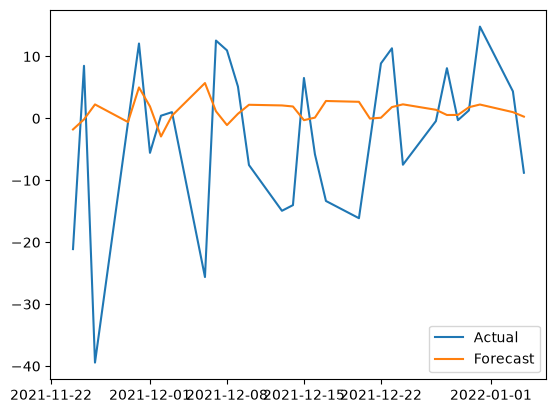

In [18]:
import matplotlib.pyplot as plt
plt.plot(test.index, test, label="Actual")  # Plot actual test values.
plt.plot(test.index, predictions, label="Forecast")  # Attach test dates to the forecast values.
plt.legend()  # Display the line labels.
plt.show()  # Display the plot.